In [2]:
import os 
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
root_path = os.path.dirname(os.getcwd())
tables_dir = root_path + "/analysis/tables/"
figures_dir = root_path + "/analysis/figures/"
os.makedirs(figures_dir, exist_ok=True)
print(root_path)
print(tables_dir)
print(figures_dir)

/home/danbi/Projects/SANAGRAPH
/home/danbi/Projects/SANAGRAPH/analysis/tables/
/home/danbi/Projects/SANAGRAPH/analysis/figures/


In [4]:
comparison = pd.read_csv(tables_dir + "main_comparison.csv")

In [5]:
patterns = ["odd", "even", "random", "attr_level", "window"]

In [6]:
pd.set_option('display.max_columns', None)

In [7]:
selected_log = "bpi_2012_CZ"

In [8]:
selected = comparison[comparison["log"] == selected_log].copy()
selected

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp
450,bpi_2012_CZ,Activity_zero,Activity,attr_level,(case) AMOUNT_REQ,numerical,mae,0.085492,0.005926,10,0.097111,0.006824,10,-0.011619,NaN
451,bpi_2012_CZ,Activity_zero,Activity,attr_level,concept:name,categorical,accuracy,0.769150,0.007689,10,0.900231,0.006175,10,0.131081,13.108149
452,bpi_2012_CZ,Activity_zero,Activity,attr_level,lifecycle:transition,categorical,accuracy,0.885707,0.004483,10,0.959746,0.003311,10,0.074039,7.403905
453,bpi_2012_CZ,Activity_zero,Activity,attr_level,org:resource,categorical,accuracy,0.634587,0.005648,10,0.657314,0.008469,10,0.022728,2.272766
454,bpi_2012_CZ,Activity_zero,Activity,attr_level,time:timestamp,numerical,mae,0.022713,0.003731,10,0.028755,0.005643,10,-0.006042,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,(case) AMOUNT_REQ,numerical,mae,0.022815,0.006955,10,0.022873,0.014749,10,-0.000057,NaN
596,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,Activity,categorical,accuracy,0.899652,0.005522,10,0.893724,0.005741,10,-0.005929,-0.592853
597,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,concept:name,categorical,accuracy,0.894052,0.004837,10,0.888299,0.003204,10,-0.005753,-0.575303
598,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,lifecycle:transition,categorical,accuracy,0.958220,0.003811,10,0.956749,0.005061,10,-0.001471,-0.147095


In [9]:
selected["variant_label"] = np.where(
    selected['model'] == "Activity_zero",
    "Activity zeroed",
    "Without " + selected['excluded_feature'],
)
selected

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label
450,bpi_2012_CZ,Activity_zero,Activity,attr_level,(case) AMOUNT_REQ,numerical,mae,0.085492,0.005926,10,0.097111,0.006824,10,-0.011619,NaN,Activity zeroed
451,bpi_2012_CZ,Activity_zero,Activity,attr_level,concept:name,categorical,accuracy,0.769150,0.007689,10,0.900231,0.006175,10,0.131081,13.108149,Activity zeroed
452,bpi_2012_CZ,Activity_zero,Activity,attr_level,lifecycle:transition,categorical,accuracy,0.885707,0.004483,10,0.959746,0.003311,10,0.074039,7.403905,Activity zeroed
453,bpi_2012_CZ,Activity_zero,Activity,attr_level,org:resource,categorical,accuracy,0.634587,0.005648,10,0.657314,0.008469,10,0.022728,2.272766,Activity zeroed
454,bpi_2012_CZ,Activity_zero,Activity,attr_level,time:timestamp,numerical,mae,0.022713,0.003731,10,0.028755,0.005643,10,-0.006042,NaN,Activity zeroed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,(case) AMOUNT_REQ,numerical,mae,0.022815,0.006955,10,0.022873,0.014749,10,-0.000057,NaN,Without time:timestamp
596,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,Activity,categorical,accuracy,0.899652,0.005522,10,0.893724,0.005741,10,-0.005929,-0.592853,Without time:timestamp
597,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,concept:name,categorical,accuracy,0.894052,0.004837,10,0.888299,0.003204,10,-0.005753,-0.575303,Without time:timestamp
598,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,window,lifecycle:transition,categorical,accuracy,0.958220,0.003811,10,0.956749,0.005061,10,-0.001471,-0.147095,Without time:timestamp


In [10]:
available_variants = selected[["model", "excluded_feature", "variant_label"]].drop_duplicates()
display(available_variants.reset_index(drop=True))

,model,excluded_feature,variant_label
0,Activity_zero,Activity,Activity zeroed
1,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,Without (case) AMOUNT_REQ
2,ablate::concept:name,concept:name,Without concept:name
3,ablate::lifecycle:transition,lifecycle:transition,Without lifecycle:transition
4,ablate::org:resource,org:resource,Without org:resource
5,ablate::time:timestamp,time:timestamp,Without time:timestamp


In [11]:
print("Available targets: ", selected["target"].unique())

Available targets:  ['(case) AMOUNT_REQ' 'concept:name' 'lifecycle:transition' 'org:resource'
 'time:timestamp' 'Activity']


In [12]:
selected_pattern = "random"
selected_target = "org:resource"
selected_feature = "time:timestamp"

rows = removed attributes, columns = reconstructed targets.
Positive = worsening compared to the baseline. Negative = improvement compared to the baseline.
For the accuracy I show the point in percetile, while for the MAE the increase of the error.

In [13]:
pattern_results = selected[selected["pattern"] == selected_pattern] 
accuracy_matrix = pattern_results[pattern_results.kind == "categorical"].pivot(index="variant_label", columns="target", values="delta_accuracy_pp")
pattern_results

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label
465,bpi_2012_CZ,Activity_zero,Activity,random,(case) AMOUNT_REQ,numerical,mae,0.078172,0.005443,10,0.083883,0.008855,10,-0.005711,NaN,Activity zeroed
466,bpi_2012_CZ,Activity_zero,Activity,random,concept:name,categorical,accuracy,0.770042,0.007930,10,0.792672,0.006770,10,0.022630,2.263025,Activity zeroed
467,bpi_2012_CZ,Activity_zero,Activity,random,lifecycle:transition,categorical,accuracy,0.880265,0.002560,10,0.890261,0.002486,10,0.009996,0.999579,Activity zeroed
468,bpi_2012_CZ,Activity_zero,Activity,random,org:resource,categorical,accuracy,0.638853,0.004218,10,0.641731,0.007014,10,0.002878,0.287815,Activity zeroed
469,bpi_2012_CZ,Activity_zero,Activity,random,time:timestamp,numerical,mae,0.015772,0.004462,10,0.017747,0.004902,10,-0.001975,NaN,Activity zeroed
490,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,Activity,categorical,accuracy,0.793092,0.003531,10,0.772324,0.010323,10,-0.020769,-2.076892,Without (case) AMOUNT_REQ
491,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,concept:name,categorical,accuracy,0.801874,0.004991,10,0.792672,0.006770,10,-0.009202,-0.920167,Without (case) AMOUNT_REQ
492,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,lifecycle:transition,categorical,accuracy,0.897084,0.002755,10,0.890261,0.002486,10,-0.006824,-0.682353,Without (case) AMOUNT_REQ
493,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,org:resource,categorical,accuracy,0.654849,0.005460,10,0.641731,0.007014,10,-0.013118,-1.311765,Without (case) AMOUNT_REQ
494,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,time:timestamp,numerical,mae,0.014100,0.000913,10,0.017747,0.004902,10,-0.003646,NaN,Without (case) AMOUNT_REQ


In [14]:
accuracy_matrix

target,Activity,concept:name,lifecycle:transition,org:resource
variant_label,,,,
Activity zeroed,NaN,2.263025,0.999579,0.287815
Without (case) AMOUNT_REQ,-2.076892,-0.920167,-0.682353,-1.311765
Without concept:name,0.069748,NaN,0.034874,-0.295379
Without lifecycle:transition,1.064706,0.015966,NaN,-0.050841
Without org:resource,0.593276,0.146219,0.504201,NaN
Without time:timestamp,-0.771008,-0.609244,-0.016807,-0.471009


In [15]:
mae_matrix = pattern_results[pattern_results.kind == "numerical"].pivot(index="variant_label", columns="target", values="delta")

In [16]:
mae_matrix

target,(case) AMOUNT_REQ,time:timestamp
variant_label,,
Activity zeroed,-0.005711,-0.001975
Without (case) AMOUNT_REQ,NaN,-0.003646
Without concept:name,-0.004696,-0.002627
Without lifecycle:transition,-0.004139,0.000774
Without org:resource,0.003493,-0.001414
Without time:timestamp,-0.001756,NaN


### Which removal change more the rebuild of a target?

Fixed a dataset, pattern and target: all the bars measure the same metric. \
Red at right = worsening. 
Green at left = improvement. 
The line at zero is the mean of the baseline. 


In [17]:
target_results = pattern_results[pattern_results["target"] == selected_target].copy()
target_results

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label
468,bpi_2012_CZ,Activity_zero,Activity,random,org:resource,categorical,accuracy,0.638853,0.004218,10,0.641731,0.007014,10,0.002878,0.287815,Activity zeroed
493,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,org:resource,categorical,accuracy,0.654849,0.005460,10,0.641731,0.007014,10,-0.013118,-1.311765,Without (case) AMOUNT_REQ
518,bpi_2012_CZ,ablate::concept:name,concept:name,random,org:resource,categorical,accuracy,0.644685,0.006605,10,0.641731,0.007014,10,-0.002954,-0.295379,Without concept:name
543,bpi_2012_CZ,ablate::lifecycle:transition,lifecycle:transition,random,org:resource,categorical,accuracy,0.642240,0.006279,10,0.641731,0.007014,10,-0.000508,-0.050841,Without lifecycle:transition
594,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,random,org:resource,categorical,accuracy,0.646441,0.007347,10,0.641731,0.007014,10,-0.004710,-0.471009,Without time:timestamp


In [18]:
accuracy_matrix.round(3)

target,Activity,concept:name,lifecycle:transition,org:resource
variant_label,,,,
Activity zeroed,NaN,2.263,1.000,0.288
Without (case) AMOUNT_REQ,-2.077,-0.920,-0.682,-1.312
Without concept:name,0.070,NaN,0.035,-0.295
Without lifecycle:transition,1.065,0.016,NaN,-0.051
Without org:resource,0.593,0.146,0.504,NaN
Without time:timestamp,-0.771,-0.609,-0.017,-0.471


In [19]:
mae_matrix.round(3)

target,(case) AMOUNT_REQ,time:timestamp
variant_label,,
Activity zeroed,-0.006,-0.002
Without (case) AMOUNT_REQ,NaN,-0.004
Without concept:name,-0.005,-0.003
Without lifecycle:transition,-0.004,0.001
Without org:resource,0.003,-0.001
Without time:timestamp,-0.002,NaN


In [20]:
is_categorical = target_results.kind.iloc[0] == "categorical"
is_categorical

True

In [21]:
scale = 100 if is_categorical else 1

In [22]:
unit = "percentage points" if is_categorical else "MAE"

In [23]:
target_results["effect"] = scale * target_results["delta"]
target_results = target_results.sort_values("effect", ascending=False)

In [24]:
target_results

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label,effect
468,bpi_2012_CZ,Activity_zero,Activity,random,org:resource,categorical,accuracy,0.638853,0.004218,10,0.641731,0.007014,10,0.002878,0.287815,Activity zeroed,0.287815
543,bpi_2012_CZ,ablate::lifecycle:transition,lifecycle:transition,random,org:resource,categorical,accuracy,0.642240,0.006279,10,0.641731,0.007014,10,-0.000508,-0.050841,Without lifecycle:transition,-0.050841
518,bpi_2012_CZ,ablate::concept:name,concept:name,random,org:resource,categorical,accuracy,0.644685,0.006605,10,0.641731,0.007014,10,-0.002954,-0.295379,Without concept:name,-0.295379
594,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,random,org:resource,categorical,accuracy,0.646441,0.007347,10,0.641731,0.007014,10,-0.004710,-0.471009,Without time:timestamp,-0.471009
493,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,org:resource,categorical,accuracy,0.654849,0.005460,10,0.641731,0.007014,10,-0.013118,-1.311765,Without (case) AMOUNT_REQ,-1.311765


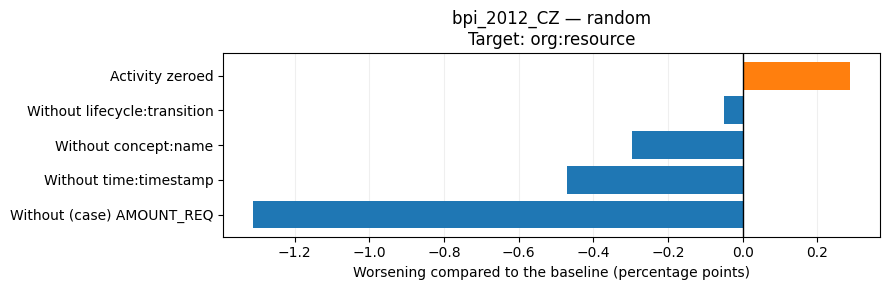

In [41]:
fig, ax = plt.subplots(figsize=(9, max(3, 0.48 * len(target_results))))
y = np.arange(len(target_results))
colors = ["tab:orange" if value > 0 else "tab:blue"
          for value in target_results.effect]

ax.barh(y, target_results.effect, color=colors)
ax.set_yticks(y, target_results.variant_label)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("Worsening compared to the baseline (" + unit + ")")
ax.set_title(f"{selected_log} — {selected_pattern}\nTarget: {selected_target}")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()

safe_target = re.sub(r"[^A-Za-z0-9_.-]+", "_", selected_target)
figure_path = figures_dir + f"02_effect_{selected_log}_{selected_pattern}_{safe_target}.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

In [26]:
across_patterns = selected[selected["target"] == selected_target].copy()
across_patterns["effect"] = scale * across_patterns["delta"]

In [27]:
pattern_table = across_patterns.pivot(
    index="variant_label", columns="pattern", values="effect"
).reindex(columns=patterns)

In [28]:
pattern_table

pattern,odd,even,random,attr_level,window
variant_label,,,,,
Activity zeroed,1.935331,2.389899,0.287815,2.272766,0.390236
Without (case) AMOUNT_REQ,-0.984241,-0.791346,-1.311765,-1.720102,-1.189534
Without concept:name,0.401705,0.356635,-0.295379,0.523290,0.339821
Without lifecycle:transition,0.326790,0.276117,-0.050841,0.763323,0.373963
Without time:timestamp,-0.384914,-0.346875,-0.471009,-0.496014,-0.362157


In [29]:
across_patterns

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label,effect
453,bpi_2012_CZ,Activity_zero,Activity,attr_level,org:resource,categorical,accuracy,0.634587,0.005648,10,0.657314,0.008469,10,0.022728,2.272766,Activity zeroed,2.272766
458,bpi_2012_CZ,Activity_zero,Activity,even,org:resource,categorical,accuracy,0.770123,0.004695,10,0.794022,0.006024,10,0.023899,2.389899,Activity zeroed,2.389899
463,bpi_2012_CZ,Activity_zero,Activity,odd,org:resource,categorical,accuracy,0.754224,0.003857,10,0.773577,0.008245,10,0.019353,1.935331,Activity zeroed,1.935331
468,bpi_2012_CZ,Activity_zero,Activity,random,org:resource,categorical,accuracy,0.638853,0.004218,10,0.641731,0.007014,10,0.002878,0.287815,Activity zeroed,0.287815
473,bpi_2012_CZ,Activity_zero,Activity,window,org:resource,categorical,accuracy,0.713736,0.005920,10,0.717639,0.010028,10,0.003902,0.390236,Activity zeroed,0.390236
478,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,attr_level,org:resource,categorical,accuracy,0.674515,0.005012,10,0.657314,0.008469,10,-0.017201,-1.720102,Without (case) AMOUNT_REQ,-1.720102
483,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,even,org:resource,categorical,accuracy,0.801936,0.004776,10,0.794022,0.006024,10,-0.007913,-0.791346,Without (case) AMOUNT_REQ,-0.791346
488,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,odd,org:resource,categorical,accuracy,0.783419,0.005492,10,0.773577,0.008245,10,-0.009842,-0.984241,Without (case) AMOUNT_REQ,-0.984241
493,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,random,org:resource,categorical,accuracy,0.654849,0.005460,10,0.641731,0.007014,10,-0.013118,-1.311765,Without (case) AMOUNT_REQ,-1.311765
498,bpi_2012_CZ,ablate::(case) AMOUNT_REQ,(case) AMOUNT_REQ,window,org:resource,categorical,accuracy,0.729534,0.005729,10,0.717639,0.010028,10,-0.011895,-1.189534,Without (case) AMOUNT_REQ,-1.189534


In [30]:
feature_results = selected[selected["excluded_feature"] == selected_feature].copy()
feature_results

,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label
575,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,attr_level,(case) AMOUNT_REQ,numerical,mae,0.093609,0.007491,10,0.097111,0.006824,10,-0.003502,NaN,Without time:timestamp
576,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,attr_level,Activity,categorical,accuracy,0.901905,0.006573,10,0.895354,0.006970,10,-0.006551,-0.655104,Without time:timestamp
577,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,attr_level,concept:name,categorical,accuracy,0.904614,0.005763,10,0.900231,0.006175,10,-0.004383,-0.438312,Without time:timestamp
578,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,attr_level,lifecycle:transition,categorical,accuracy,0.962126,0.002133,10,0.959746,0.003311,10,-0.002380,-0.238006,Without time:timestamp
579,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,attr_level,org:resource,categorical,accuracy,0.662274,0.007198,10,0.657314,0.008469,10,-0.004960,-0.496014,Without time:timestamp
580,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,even,(case) AMOUNT_REQ,numerical,mae,0.025167,0.010459,10,0.025661,0.012174,10,-0.000494,NaN,Without time:timestamp
581,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,even,Activity,categorical,accuracy,0.925993,0.002334,10,0.923232,0.001758,10,-0.002761,-0.276117,Without time:timestamp
582,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,even,concept:name,categorical,accuracy,0.925700,0.002729,10,0.923879,0.003012,10,-0.001822,-0.182181,Without time:timestamp
583,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,even,lifecycle:transition,categorical,accuracy,0.989557,0.002604,10,0.989346,0.001280,10,-0.000211,-0.021147,Without time:timestamp
584,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,even,org:resource,categorical,accuracy,0.797491,0.005239,10,0.794022,0.006024,10,-0.003469,-0.346875,Without time:timestamp


In [31]:
pair = feature_results[feature_results["target"] == selected_target].set_index("pattern").reindex(patterns)
pair

,log,model,excluded_feature,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label
pattern,,,,,,,,,,,,,,,
odd,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,org:resource,categorical,accuracy,0.777426,0.006339,10,0.773577,0.008245,10,-0.003849,-0.384914,Without time:timestamp
even,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,org:resource,categorical,accuracy,0.797491,0.005239,10,0.794022,0.006024,10,-0.003469,-0.346875,Without time:timestamp
random,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,org:resource,categorical,accuracy,0.646441,0.007347,10,0.641731,0.007014,10,-0.004710,-0.471009,Without time:timestamp
attr_level,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,org:resource,categorical,accuracy,0.662274,0.007198,10,0.657314,0.008469,10,-0.004960,-0.496014,Without time:timestamp
window,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,org:resource,categorical,accuracy,0.721260,0.007526,10,0.717639,0.010028,10,-0.003622,-0.362157,Without time:timestamp


In [32]:
variant_label = pair["variant_label"].iloc[0]

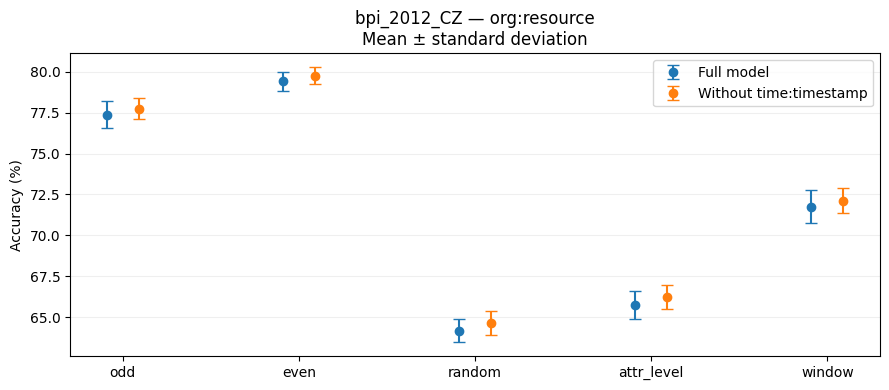

In [44]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(patterns))

ax.errorbar(x - 0.09, scale * pair.full_mean,
            yerr=scale * pair.full_std,
            fmt="o", capsize=4, label="Full model")

ax.errorbar(x + 0.09, scale * pair.variant_mean,
            yerr=scale * pair.variant_std,
            fmt="o", capsize=4, label=variant_label)

ax.set_xticks(x, patterns)
ax.set_ylabel("Accuracy (%)" if is_categorical else "MAE")
ax.set_title(f"{selected_log} — {selected_target}\nMean ± standard deviation")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()

safe_feature = re.sub(r"[^A-Za-z0-9_.-]+", "_", selected_feature)
fig.savefig(figures_dir + f"02_means_{selected_log}_{safe_feature}_{safe_target}.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [46]:
feature_pattern = feature_results[feature_results.pattern == selected_pattern]

print(variant_label, "—", selected_pattern)

print("Categorical targets: delta in percentage points")
feature_pattern


Without time:timestamp — random
Categorical targets: delta in percentage points


,log,model,excluded_feature,pattern,target,kind,metric,variant_mean,variant_std,variant_n_runs,full_mean,full_std,full_n_runs,delta,delta_accuracy_pp,variant_label
590,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,random,(case) AMOUNT_REQ,numerical,mae,0.082127,0.008787,10,0.083883,0.008855,10,-0.001756,NaN,Without time:timestamp
591,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,random,Activity,categorical,accuracy,0.780034,0.005596,10,0.772324,0.010323,10,-0.007710,-0.771008,Without time:timestamp
592,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,random,concept:name,categorical,accuracy,0.798765,0.004012,10,0.792672,0.006770,10,-0.006092,-0.609244,Without time:timestamp
593,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,random,lifecycle:transition,categorical,accuracy,0.890429,0.002514,10,0.890261,0.002486,10,-0.000168,-0.016807,Without time:timestamp
594,bpi_2012_CZ,ablate::time:timestamp,time:timestamp,random,org:resource,categorical,accuracy,0.646441,0.007347,10,0.641731,0.007014,10,-0.004710,-0.471009,Without time:timestamp
